# Eaton and Palisades Fire True and False Color Imagery
by Natasha Clemencon-Charles
(https://github.com/natashaclemencon/eds220-hwk4.git)

# About 
### Purpose 
The purpose of this notebook is to visualize fire scars after the Eaton and Palisades fires in Los Angeles in 2025. 
### Highlights
Some things that stood out to me during this analysis included:
- The importance of a CRS when doing any spatial analysis. To begin, I had to set the CRS for the landsat data, and then I later needed to change it to match the CRS's of the Eaton and Palisades perimeter datasets.
- How helpful false color imagery can be for displaying certain features. With the true color imagery, it was difficult to really see the burn scars from the two fires. However, the false color imagery clearly displayed them.
- 
### Data
This project uses Landsat 8 data from the Microsoft Planetary Computer data catalog. 
Earth Resources Observation and Science (EROS) Center. (2020). Landsat 8-9 Operational Land Imager / Thermal Infrared Sensor Level-2, Collection 2 [dataset]. U.S. Geological Survey. https://doi.org/10.5066/P9OGBGM6.
This project also uses two Cal Fire datasets showing fire perimeters of the Palisades and Eaton fires, accessed from the LA County GIS Hub.
Palisades and Eaton Dissolved Fire Perimeters (2025), January 21, 2025, https://egis-lacounty.hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about

In [82]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr
import os
import geopandas as gpd

In [3]:
# Read in the Eaton fire data. 
eaton = gpd.read_file("data/Eaton_Perimeter_20250121/Eaton_Perimeter_20250121.shp")

ERROR 1: PROJ: proj_create_from_database: Open of /opt/miniforge3/envs/eds220-v2/share/proj failed


In [11]:
eaton.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [5]:
# Read in the Palisades fire data. 
palisades = gpd.read_file("data/Palisades_Perimieter_20250121/Palisades_Perimieter_20250121.shp")

In [10]:
palisades
palisades.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

Preliminary analysis of the eaton and palisades shapefiles show that they are geometric projections, and that they both have the CRS EPSG 4269. I also can see that the area of use of these two shapefiles is the North American region. 

In [13]:
# Read in the landsat data.
landsat = xr.open_dataset("data/landsat8-2025-02-23-palisades-eaton.nc")

sh: 1: getfattr: not found


In [14]:
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

From the preliminary exploration of the CDF dataset, I noticed that there are no attributes. I also see that the dimensions are y: 1418 and x: 2742, which means there are 1418 grid cells vertically, and 2742 grid cells horizontally. 
I notice that the variables are the different band colors and the CRS(WGS84). The color variables are stored as (y,x), meaning each grid cell has a particular color value according to it's location. 

In [20]:
# Find the CRS of landsat.
landsat.rio.crs

In [22]:
# The previous commmand didn't return a CRS; access it from spatial_ref. 
landsat.spatial_ref.crs_wkt

'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

In [32]:
# Recover the CRS
landsat = landsat.rio.write_crs("EPSG:32611")

In [33]:
landsat.rio.crs

CRS.from_wkt('PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]')

Preliminary analysis of the fires shapefile shows that it has a CRS of WGS 84, and is a geographic projection.

## 5: True Color Image

/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


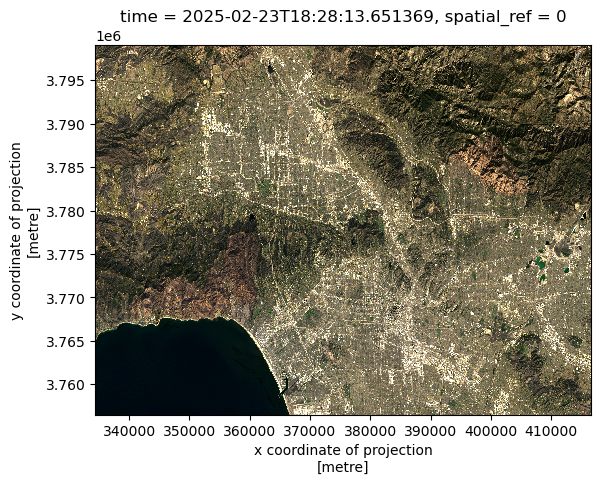

In [51]:
#a/b Plot the landsat data of the LA area. 
landsat[["red", "green", "blue"]].to_dataarray().plot.imshow(rgb="variable", robust=True)

In [71]:
#c Find which bands have missing data.
print(np.isnan(landsat['red']).sum().values)
print(np.isnan(landsat['blue']).sum().values)
print(np.isnan(landsat['green']).sum().values)

0
109
1


In [72]:
#d Fill the NAs in landsat with 0.
landsatnona = landsat.fillna(0)

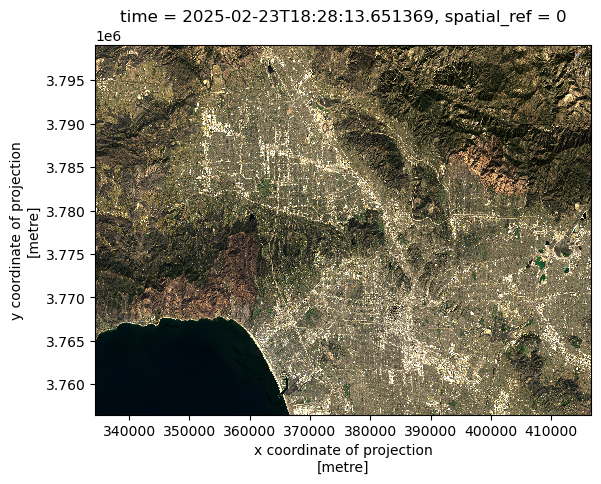

In [73]:
#e Plot the landsat data again, this time with NA's filled.
landsatnona[["red", "green", "blue"]].to_dataarray().plot.imshow(rgb="variable", robust=True)

Filling in the NAs in the landsat data with 0's didn't seem to change anything visually, which makes sense given there were only about 100 pixels missing any data, which isn't a lot compared to the amount of pixels comprising these bands. However, we no longer get a warning message. 

## 6. False Color Image

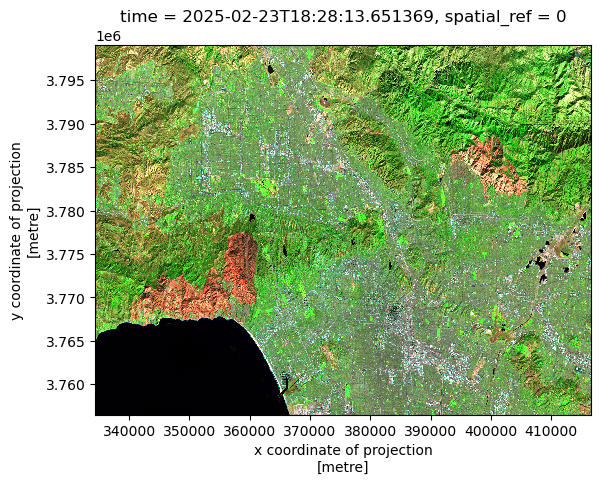

In [78]:
# Create a false color image with SWIR, NIR, and red bands.
landsatnona[["swir22", "nir08", "red"]].to_dataarray().plot.imshow(rgb="variable", robust=True)

## 7: Map

In [109]:
# Change landsat CRS to match the fires CRS's. 
landsat4269 = landsat.rio.reproject("EPSG:4269")


/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)
/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


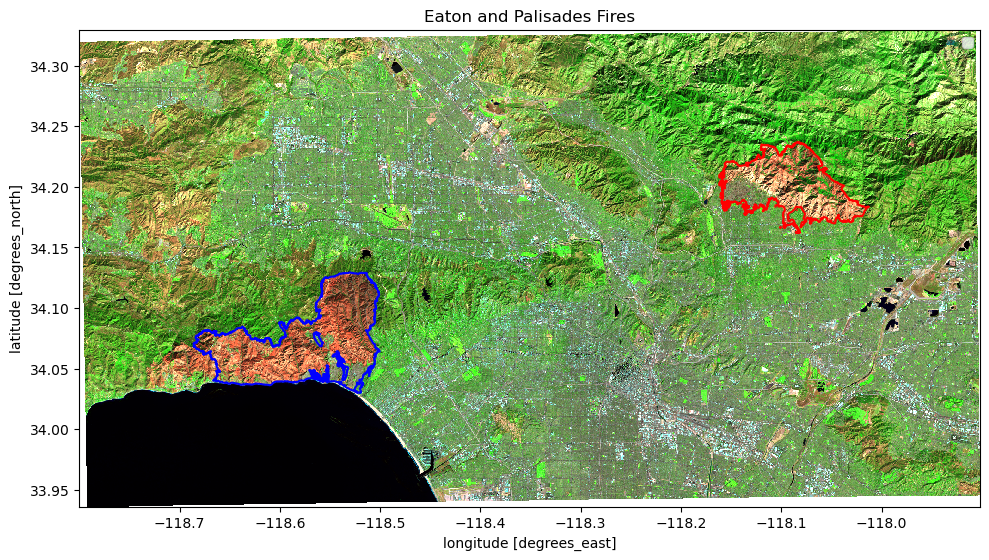

In [112]:
fig, ax = plt.subplots(1,1, figsize=(10,10))


landsat4269[["swir22", "nir08", "red"]].to_dataarray().plot.imshow(ax=ax, rgb="variable", robust=True)
palisades.boundary.plot(ax=ax, color='blue')
eaton.boundary.plot(ax=ax, color='red', )

ax.set_title('Eaton and Palisades Fires')
ax.legend()
plt.tight_layout()
plt.show()